In [1]:
import duckdb as db
import polars as pl
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from cfg import SHORT


In [2]:
DATASET = os.path.join("..", "data", "raw")
PROCESSED = os.path.join("..", "data", "processed")
DB_PATH = os.path.join("..", "data", "raw", "sintef_ocean.db")

In [3]:
short2name = {v: k for k, v in SHORT.items()}

In [4]:
conn = db.connect(database=DB_PATH)
metrics_raw_long = conn.execute("SELECT timestamp, short_name, value FROM metrics_raw").pl()
noon_reports = conn.execute("SELECT * FROM noon_reports").pl()
jan25 = conn.execute("SELECT * FROM jan25").pl()
conn.close()

In [5]:
metrics_wide = metrics_raw_long.pivot(index="timestamp", on="short_name", values="value", aggregate_function="mean").sort("timestamp")

In [6]:
metrics_wide.head()

timestamp,shaft_torque_nm,draft_midp,turn_rate,draft_mids,thrust_kn,stw_kn,s_sst,fo_kgh,wind_rel_deg,draft_aft,shaft_kwh,me_scav_bar,s_tp,shaft_kw,me_load_pct,s_hs,me_rpm,draft_fwd,shaft_revs,sog_kn,mb_wind_kn,wind_rel_kn,heading_deg,s_cur_e,shaft_rpm,mb_wind_deg,me_tc_rpm,s_wind_e,s_cur_n,s_wave_deg,mb_swell,depth_m,s_wind_n
"datetime[μs, Europe/Oslo]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-01 01:00:00 CET,null,null,null,null,null,null,6.0,null,null,null,null,null,1.1,null,null,1.355,null,null,null,null,4.06,null,null,-0.2,null,79.0,null,0.5391,-0.2,10.0,2.7,null,0.7463
2024-01-01 01:00:00.010 CET,null,null,null,null,null,0.1,null,null,82.0,null,null,null,null,null,null,null,null,null,null,0.0,null,1.1,null,null,null,null,null,null,null,null,null,null,null
2024-01-01 01:00:00.030 CET,null,null,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,120.3,null,null,null,null,null,null,null,null,6.1,null
2024-01-01 01:00:00.050 CET,null,null,null,null,null,null,null,null,null,null,null,0.023865,null,null,0.0,null,null,null,null,null,null,null,null,null,null,null,13.73291,null,null,null,null,null,null
2024-01-01 01:00:00.081 CET,null,0.0,null,0.0,null,null,null,null,null,0.0,null,null,null,null,null,null,0.0,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null


In [7]:
time_col = "timestamp"


In [ ]:
# Exclude any identifier columns here as well
columns = [c for c in metrics_wide.columns if c != time_col]
# Store the calculated gaps for later use
time_gaps = {}
for column in columns:
    gaps = (metrics_wide.filter(pl.col(column).is_not_null()
            & pl.col(time_col).is_not_null()).sort(time_col).select(
            (pl.col(time_col).diff().dt.total_microseconds()/ 1_000_000).alias("gap_seconds")).drop_nulls()
    )

    time_gaps[column] = gaps

    if gaps.is_empty():
        print(f"{column}: fewer than two observations")
        continue

    fig, ax = plt.subplots(figsize=(7, 3))

    ax.hist(
        gaps["gap_seconds"].to_numpy(),
        bins=40,
        edgecolor="white",
    )

    ax.set_title(short2name[column])
    ax.set_xlabel("Time between consecutive observations (seconds)")
    ax.set_ylabel("Frequency")

    fig.tight_layout()
    plt.show()

In [8]:
with pl.Config(tbl_cols=-1, tbl_rows=-1, fmt_str_lengths=100):
    print(metrics_wide.describe())

shape: (9, 35)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ sta ┆ tim ┆ sha ┆ dra ┆ tur ┆ dra ┆ thr ┆ stw ┆ s_s ┆ fo_ ┆ win ┆ dra ┆ sha ┆ me_ ┆ s_t ┆ sha ┆ me_ ┆ s_h ┆ me_ ┆ dra ┆ sha ┆ sog ┆ mb_ ┆ win ┆ hea ┆ s_c ┆ sha ┆ mb_ ┆ me_ ┆ s_w ┆ s_c ┆ s_w ┆ mb_ ┆ dep ┆ s_w │
│ tis ┆ est ┆ ft_ ┆ ft_ ┆ n_r ┆ ft_ ┆ ust ┆ _kn ┆ st  ┆ kgh ┆ d_r ┆ ft_ ┆ ft_ ┆ sca ┆ p   ┆ ft_ ┆ loa ┆ s   ┆ rpm ┆ ft_ ┆ ft_ ┆ _kn ┆ win ┆ d_r ┆ din ┆ ur_ ┆ ft_ ┆ win ┆ tc_ ┆ ind ┆ ur_ ┆ ave ┆ swe ┆ th_ ┆ ind │
│ tic ┆ amp ┆ tor ┆ mid ┆ ate ┆ mid ┆ _kn ┆ --- ┆ --- ┆ --- ┆ el_ ┆ aft ┆ kwh ┆ v_b ┆ --- ┆ kw  ┆ d_p ┆ --- ┆ --- ┆ fwd ┆ rev ┆ --- ┆ d_k ┆ el_ ┆ g_d ┆ e   ┆ rpm ┆ d_d ┆ rpm ┆ _e  ┆ n   ┆ _de ┆ ll  ┆ m   ┆ _n  │
│ --- ┆ --- ┆ que ┆ p   ┆ --- ┆ s   ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ deg ┆ --- ┆ --- ┆ ar  ┆ f64 ┆ --- ┆ ct  ┆ f64 ┆ f64 ┆ --- ┆ s   ┆ f64 ┆ n  

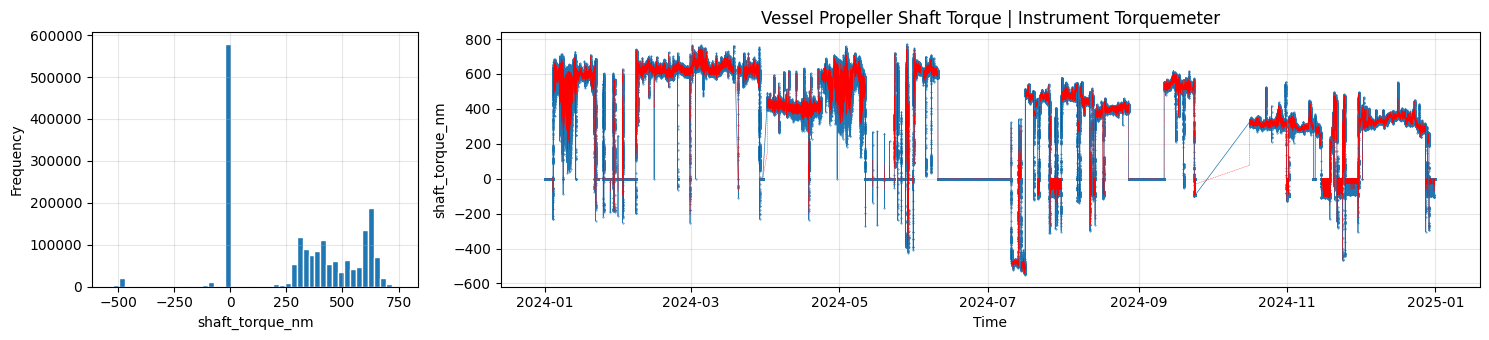

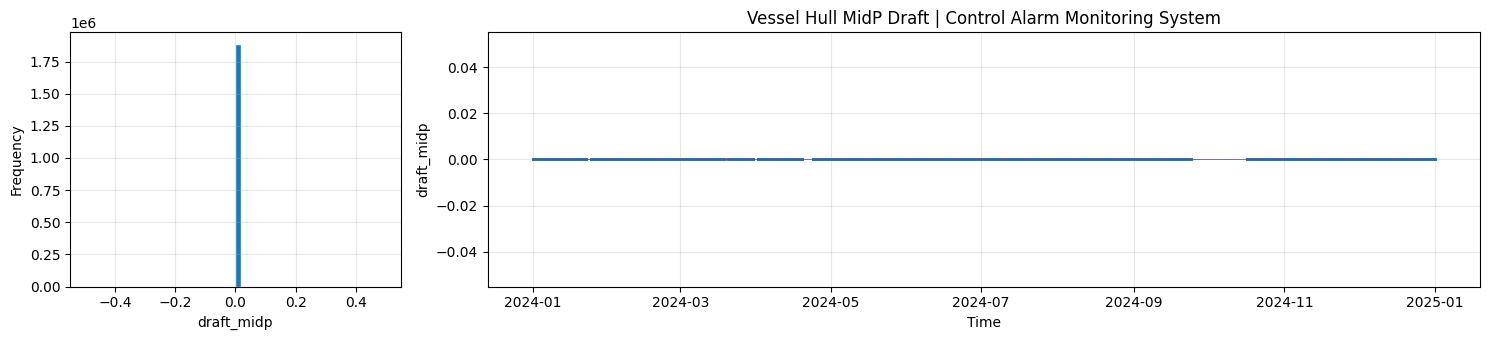

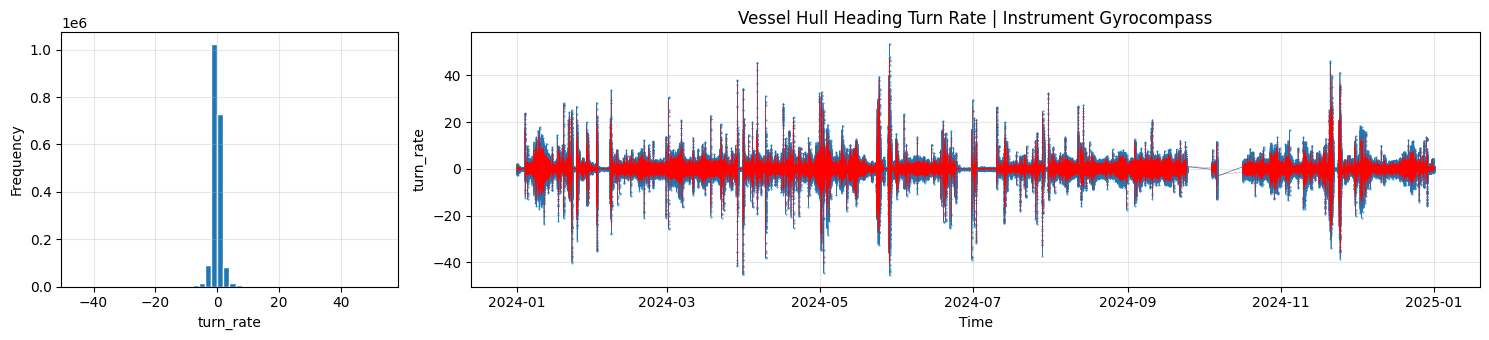

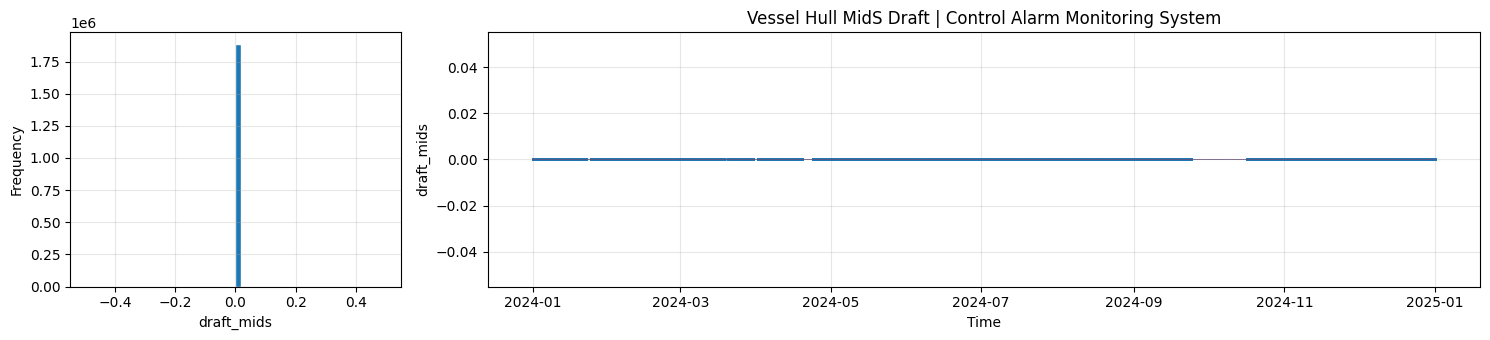

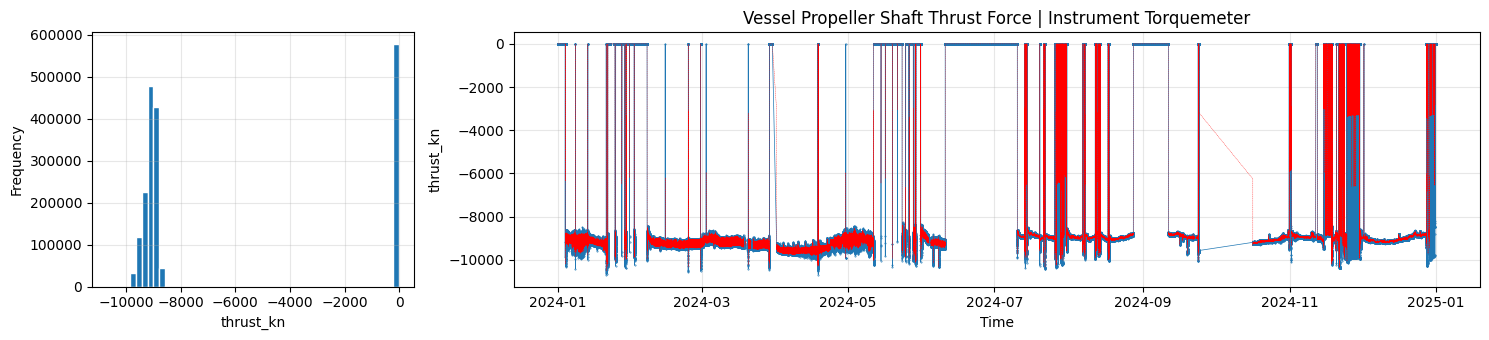

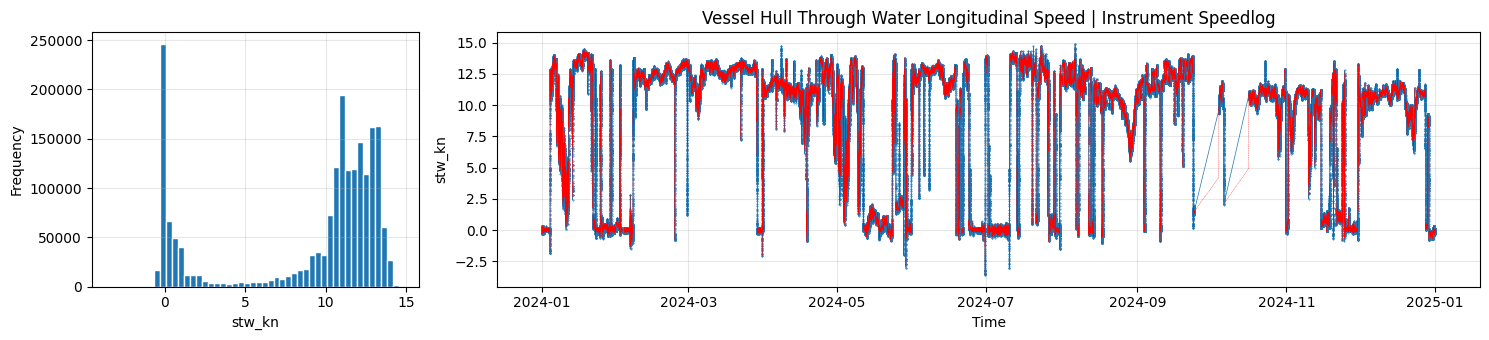

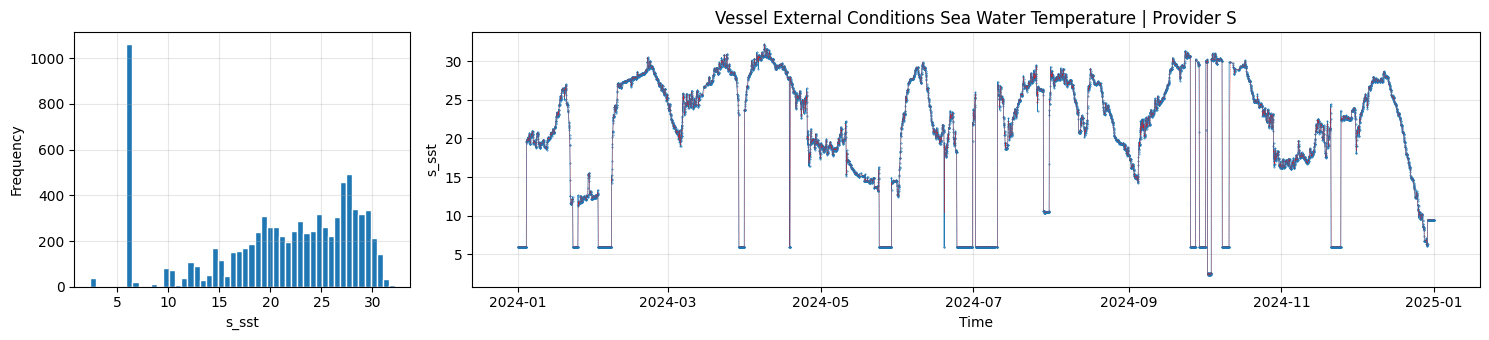

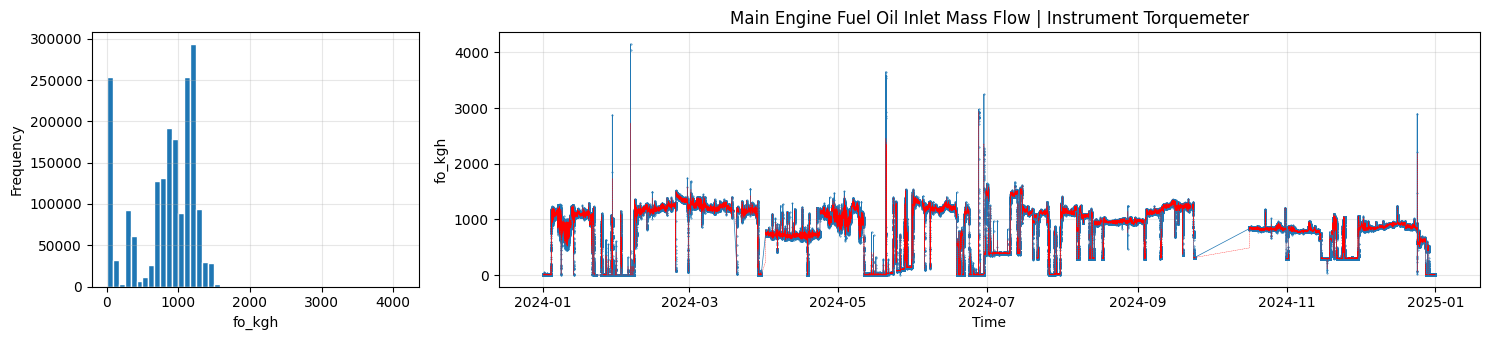

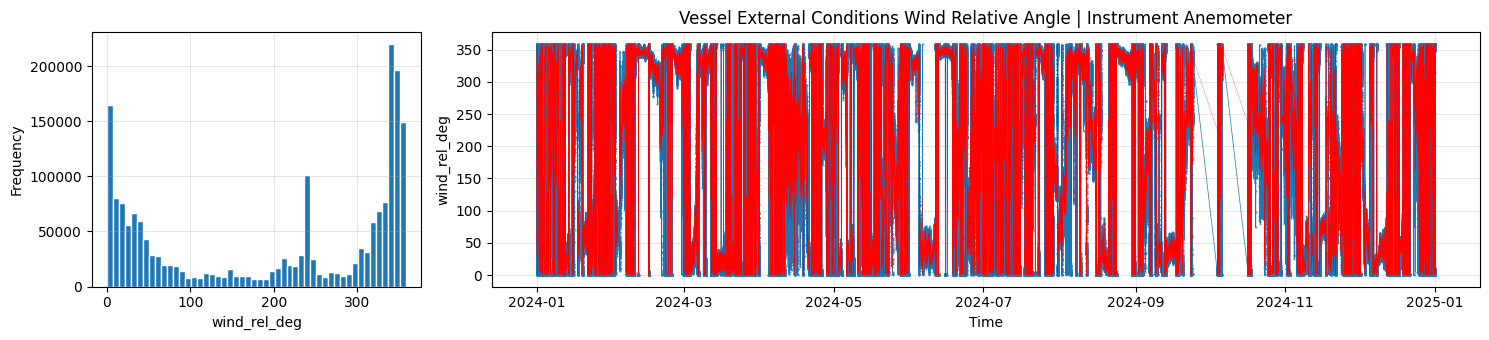

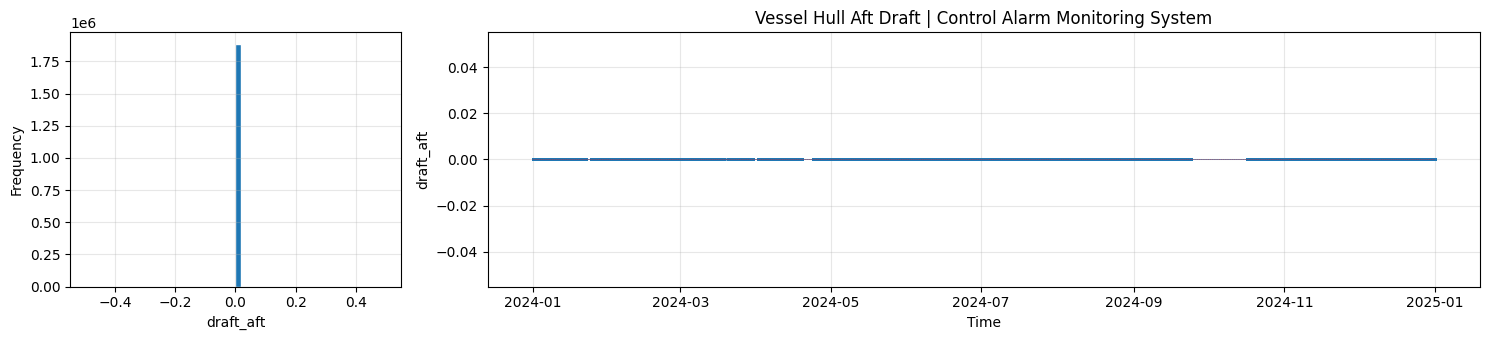

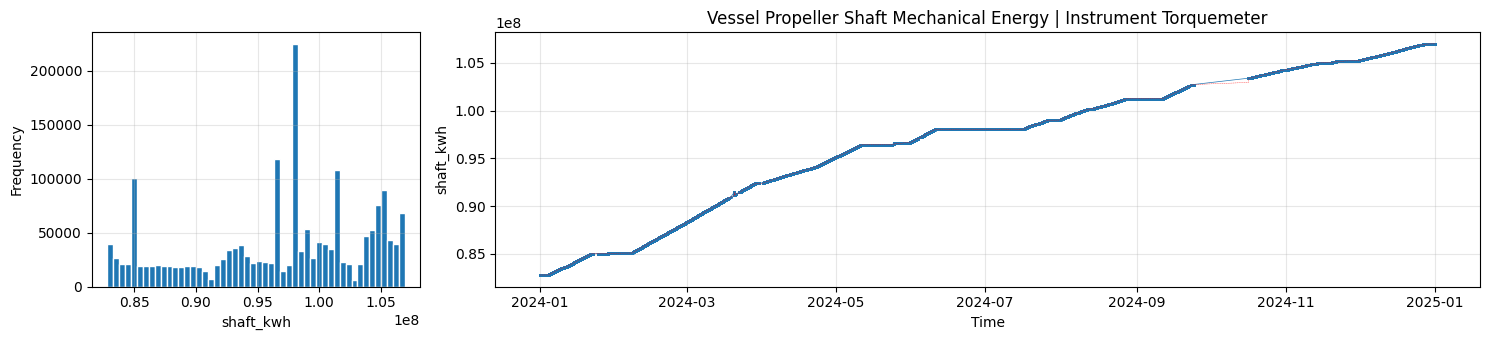

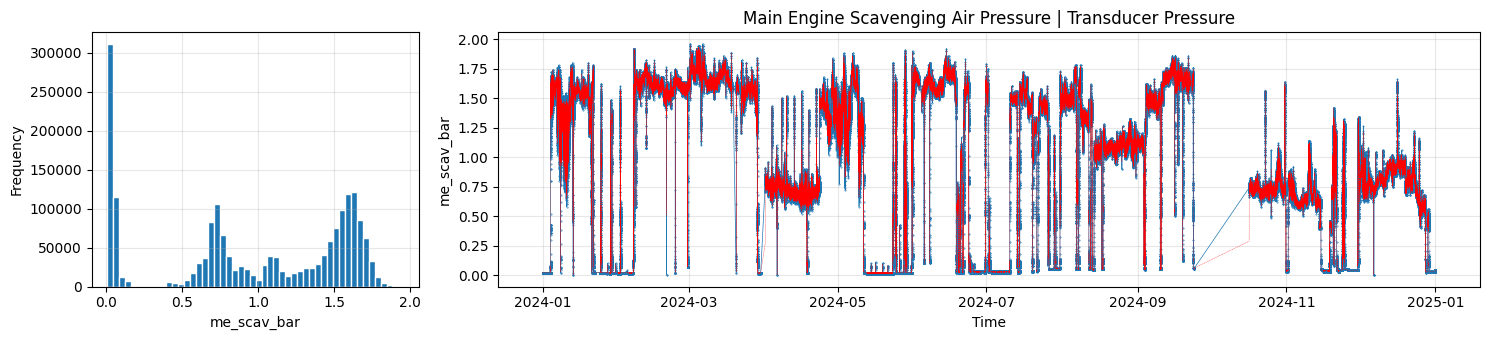

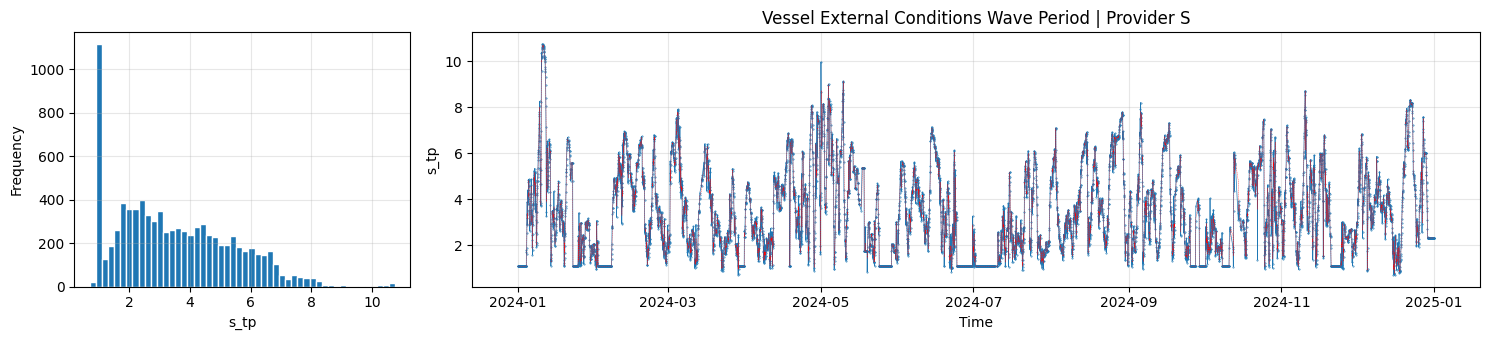

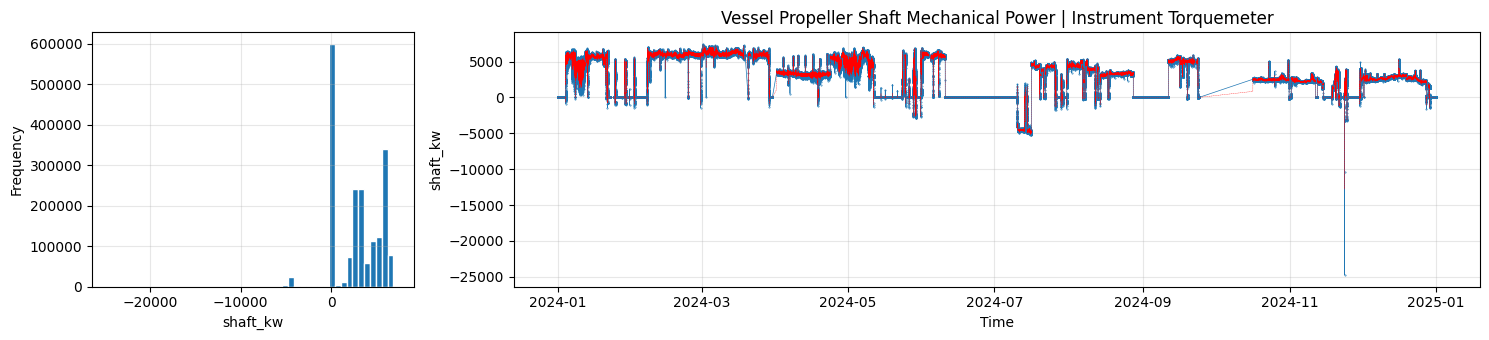

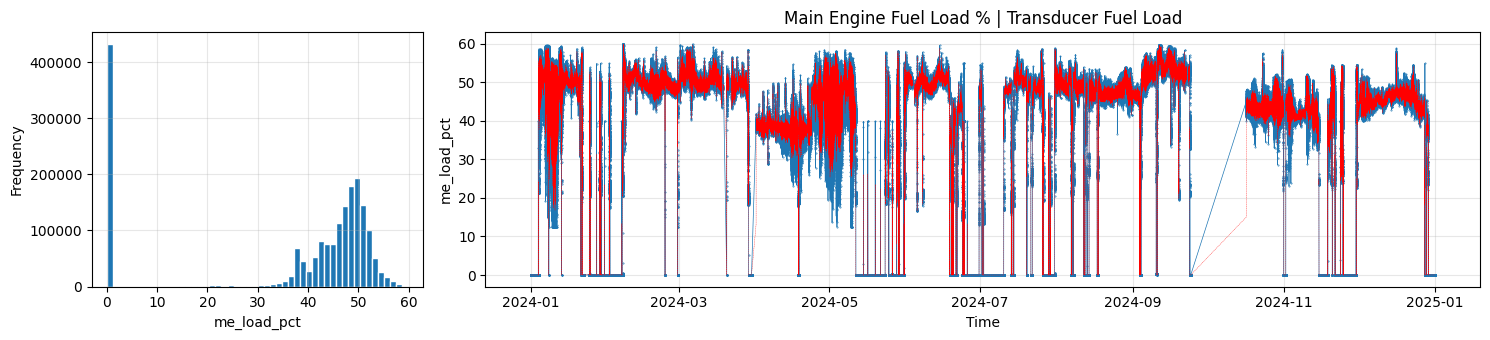

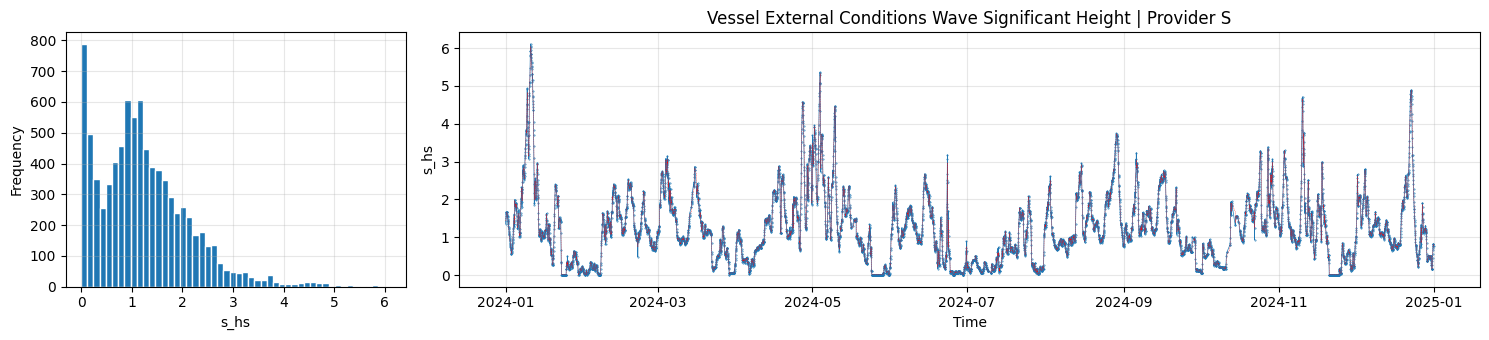

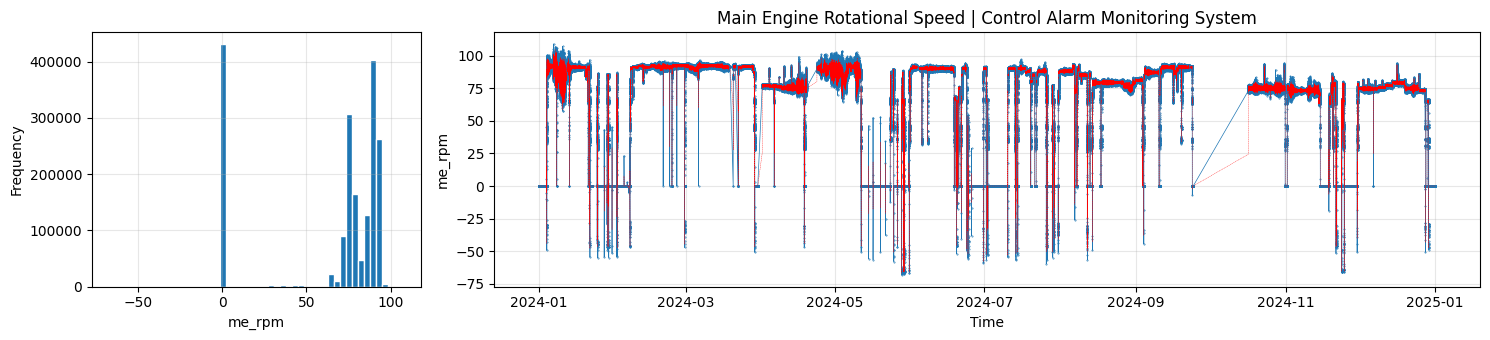

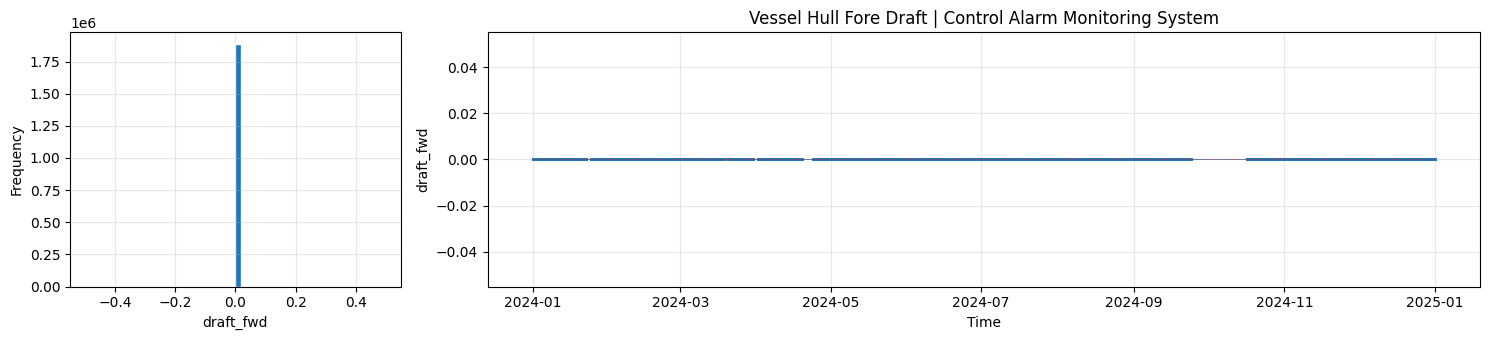

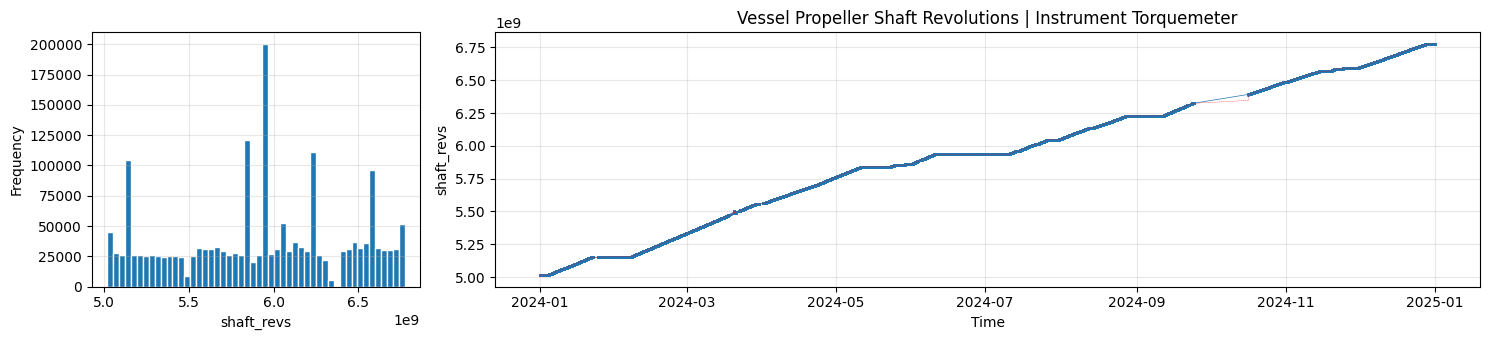

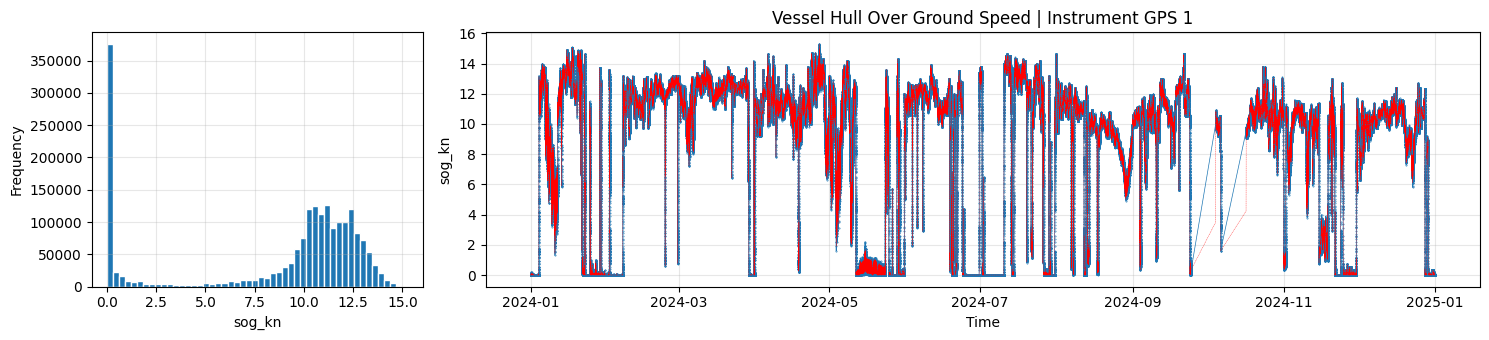

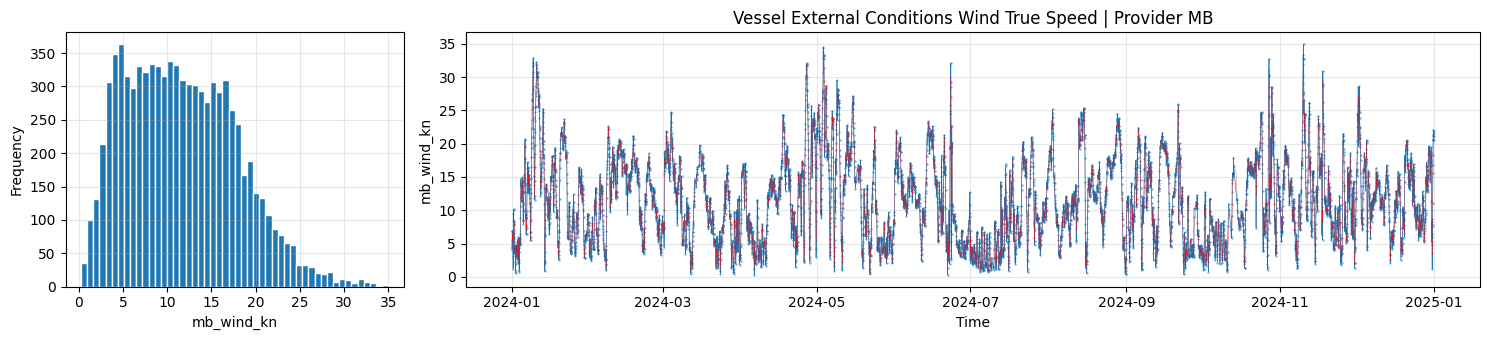

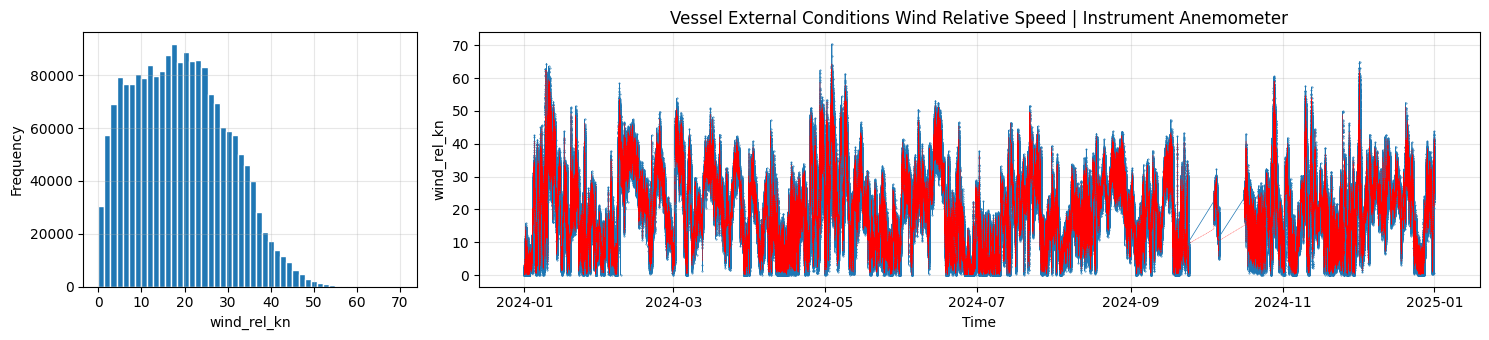

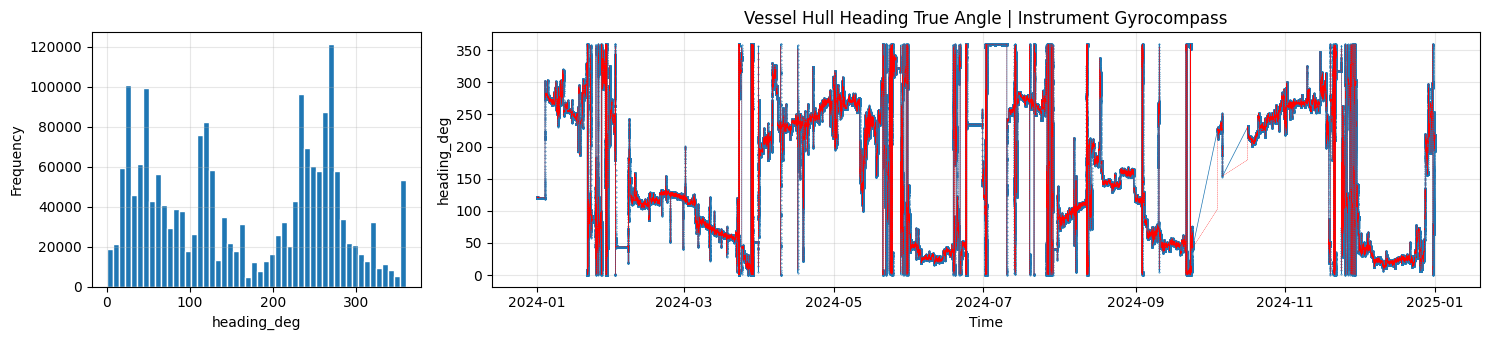

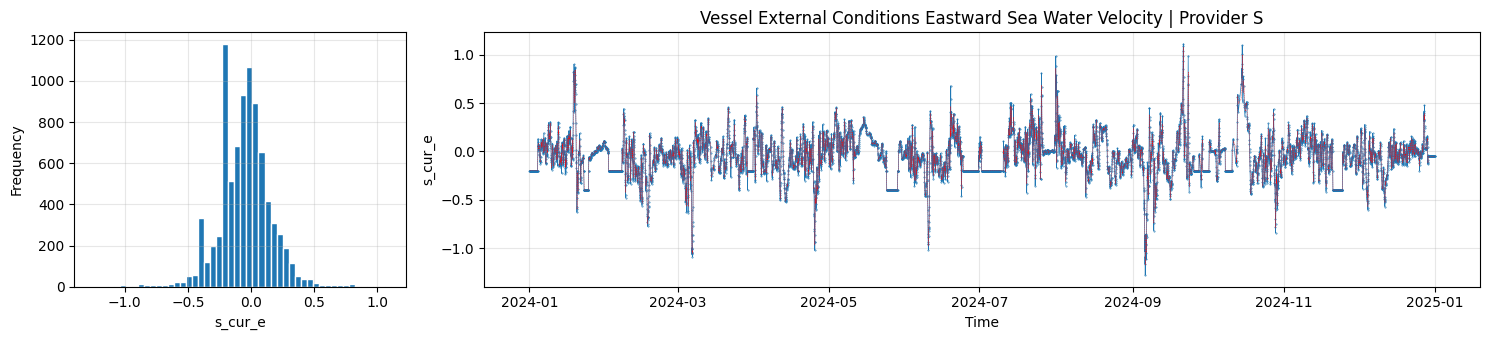

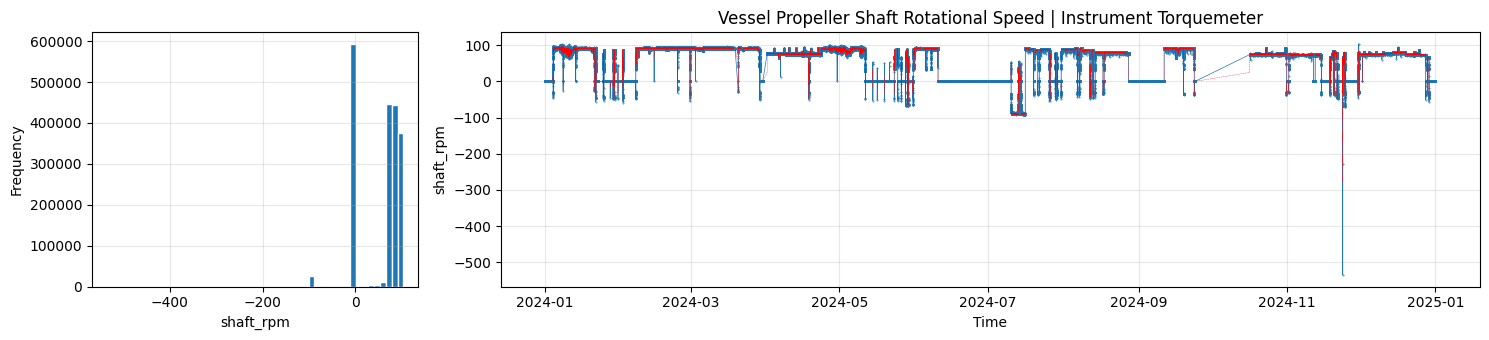

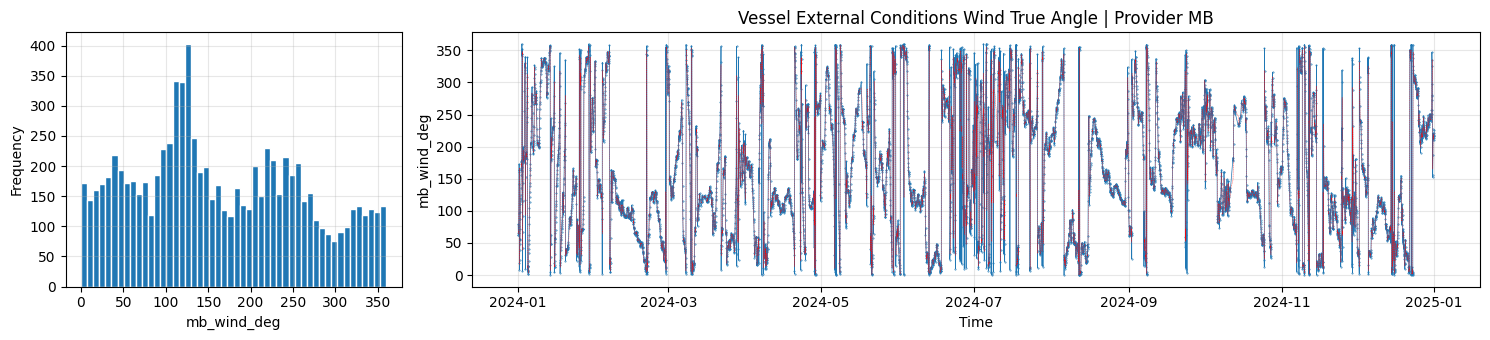

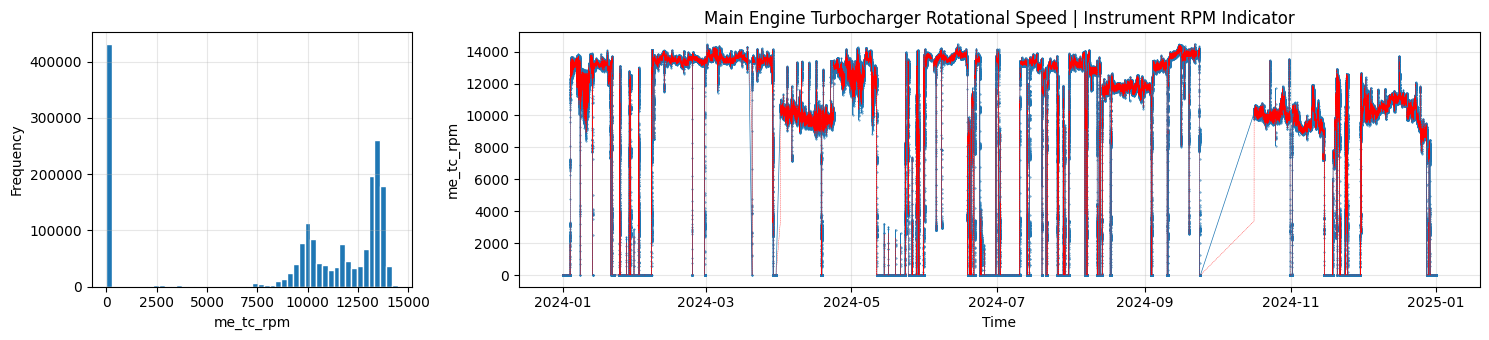

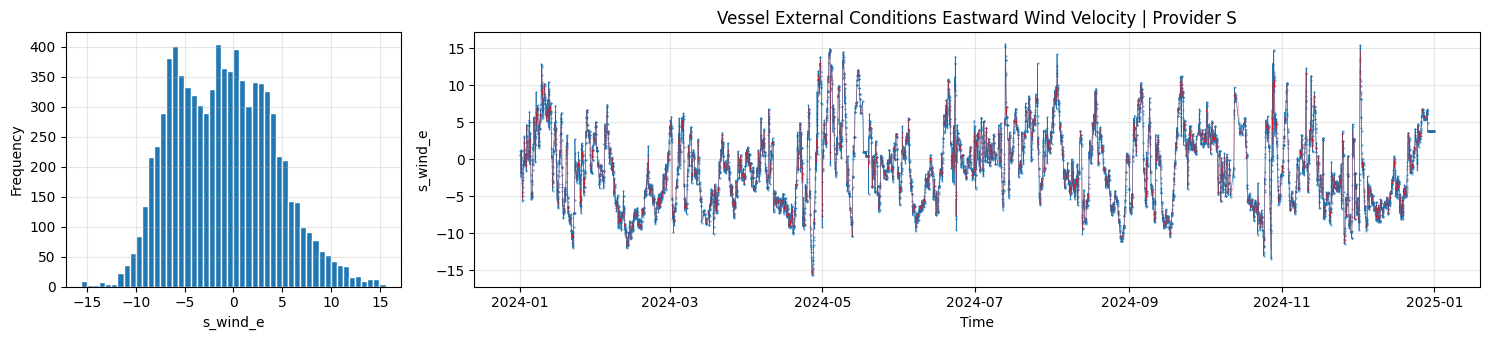

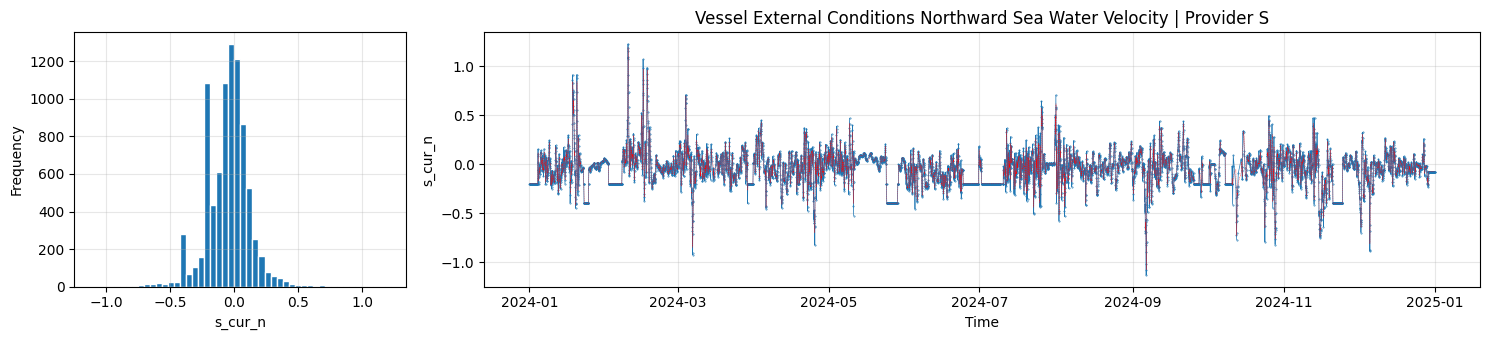

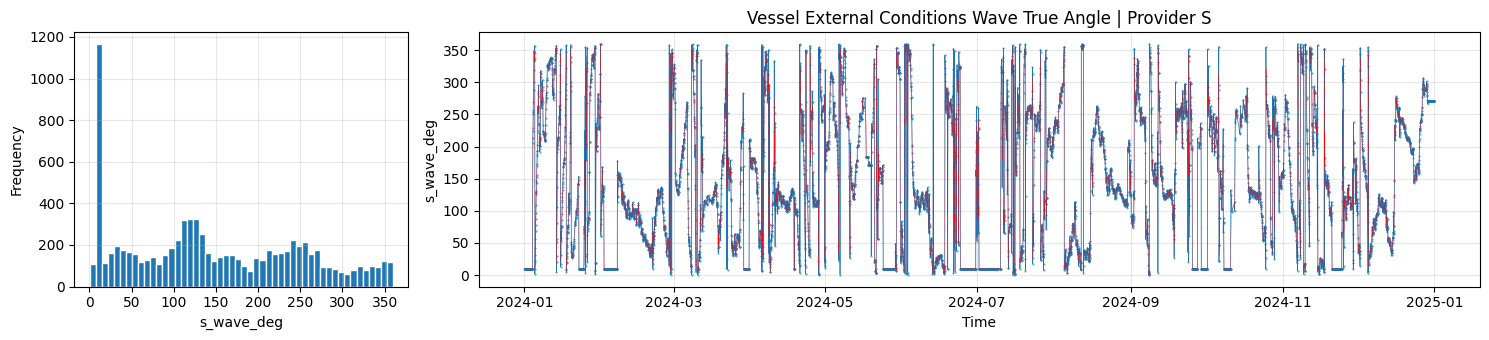

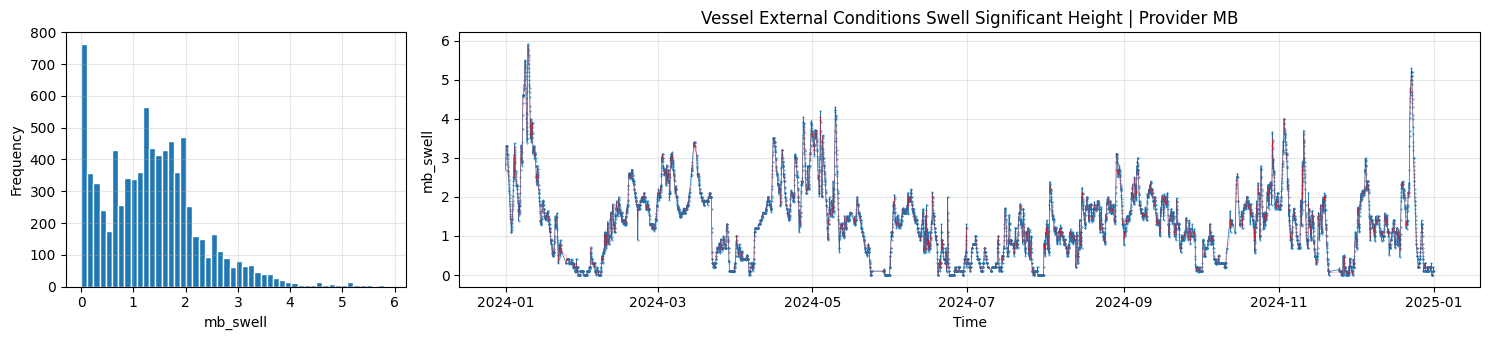

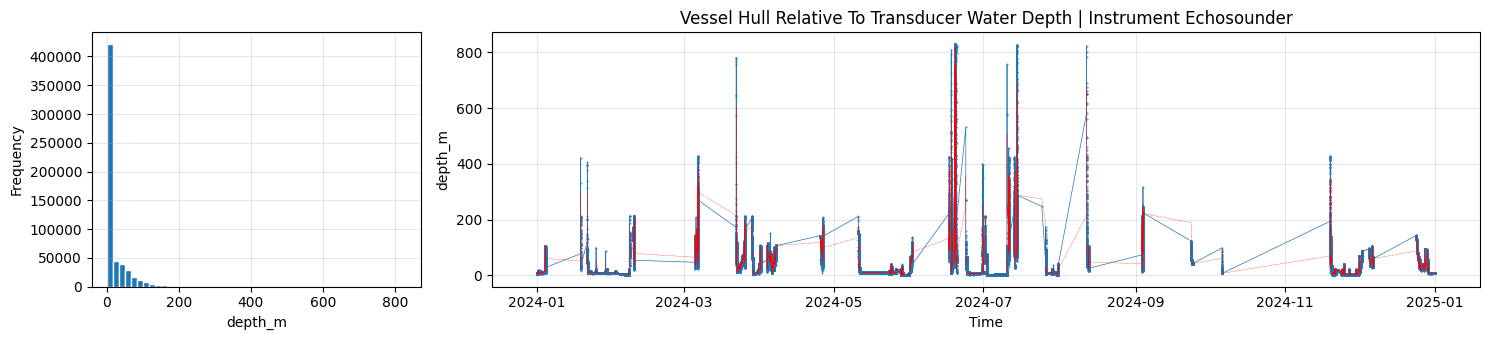

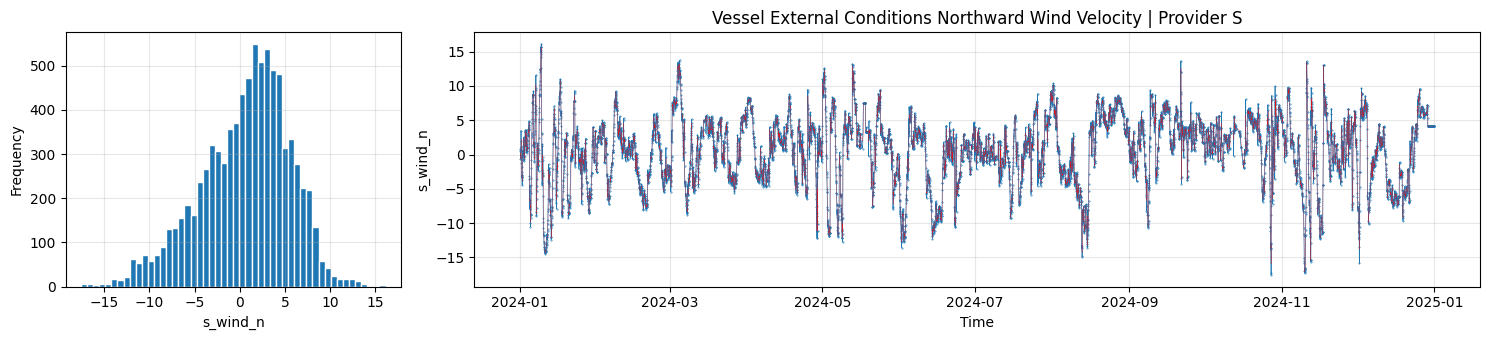

In [14]:
columns = metrics_wide.columns


for column in columns[1:]:
    data = (metrics_wide.select(time_col, column).drop_nulls().sort(time_col))
    data = data.with_columns(rolling_avg = pl.col(column).rolling_mean(window_size=3))

    if len(data[column]) == 0:
        continue

    fig, axes = plt.subplots(1,2, figsize=(15, 3.5),gridspec_kw={'width_ratios': [1,3]})

    # Histogram
    axes[0].hist(data[column], bins=50, edgecolor="white")
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Frequency")

    axes[1].plot(data[time_col].to_list(), data[column],marker = ".", markersize=0.75, linewidth=0.5, label=column)
    axes[1].plot(data[time_col].to_list(), data["rolling_avg"], color="red", linewidth=0.25, linestyle = "--", label="Rolling Mean (window=3)")
    axes[1].grid(True, alpha=0.3)
    axes[1].set_ylabel(column)
    axes[1].set_xlabel("Time")

    plt.title(short2name[column])
    fig.tight_layout()
    plt.show()

In [ ]:
#rpm vs power
#rpm vs speed

Text(0.5, 1.0, 'Shaft Energy vs Shaft Power')

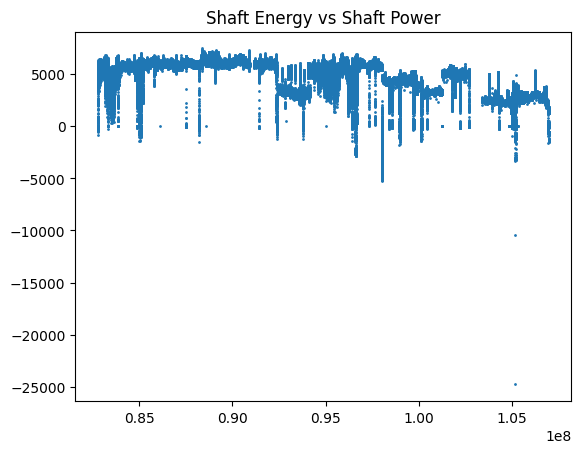

In [11]:
#["timestamp", "shaft_torque_nm", "draft_midp", "turn_rate", "draft_mids", "thrust_kn", "stw_kn", "s_sst", "fo_kgh", "wind_rel_deg", "draft_aft", "shaft_kwh", "me_scav_bar", "s_tp", "shaft_kw", "me_load_pct", "s_hs", "me_rpm", "draft_fwd", "shaft_revs", "sog_kn", "mb_wind_kn", "wind_rel_kn", "heading_deg", "s_cur_e", "shaft_rpm", "mb_wind_deg", "me_tc_rpm", "s_wind_e", "s_cur_n", "s_wave_deg", "mb_swell", "depth_m", "s_wind_n"]
shaft_energy_power = metrics_wide.select("shaft_kwh", "shaft_kw").drop_nulls().sort("shaft_kwh")
plt.scatter(shaft_energy_power["shaft_kwh"].to_numpy(), shaft_energy_power["shaft_kw"].to_numpy(), s=1)
plt.title("Shaft Energy vs Shaft Power")

Text(0.5, 1.0, 'Shaft RPM vs Shaft Power')

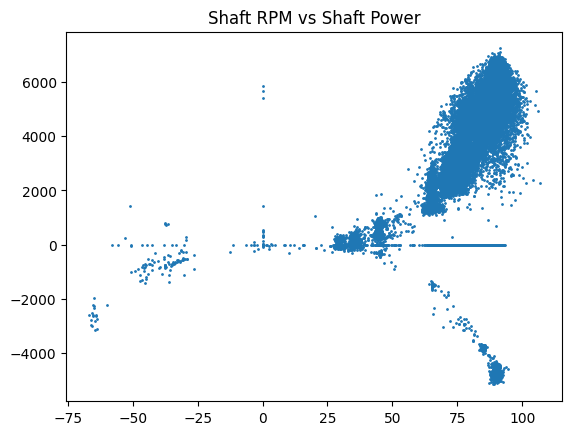

In [13]:
shaft_rpm_power = metrics_wide.select("me_rpm", "shaft_kw").drop_nulls().sort("me_rpm")
plt.scatter(shaft_rpm_power["me_rpm"].to_numpy(), shaft_rpm_power["shaft_kw"].to_numpy(), s=1)
plt.title("Shaft RPM vs Shaft Power")

In [17]:
metrics_wide.columns

['timestamp',
 'shaft_torque_nm',
 'draft_midp',
 'turn_rate',
 'draft_mids',
 'thrust_kn',
 'stw_kn',
 's_sst',
 'fo_kgh',
 'wind_rel_deg',
 'draft_aft',
 'shaft_kwh',
 'me_scav_bar',
 's_tp',
 'shaft_kw',
 'me_load_pct',
 's_hs',
 'me_rpm',
 'draft_fwd',
 'shaft_revs',
 'sog_kn',
 'mb_wind_kn',
 'wind_rel_kn',
 'heading_deg',
 's_cur_e',
 'shaft_rpm',
 'mb_wind_deg',
 'me_tc_rpm',
 's_wind_e',
 's_cur_n',
 's_wave_deg',
 'mb_swell',
 'depth_m',
 's_wind_n']

Text(0.5, 1.0, 'SOG vs Shaft Power')

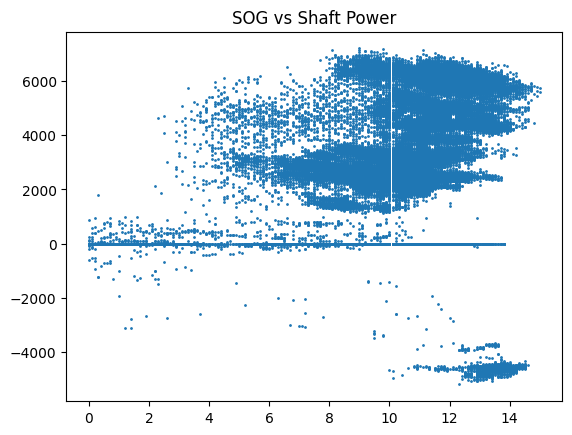

In [20]:
sog_power = metrics_wide.select("sog_kn", "shaft_kw").drop_nulls().sort("sog_kn")
plt.scatter(sog_power["sog_kn"].to_numpy(), sog_power["shaft_kw"].to_numpy(), s=1)
plt.title("SOG vs Shaft Power")

Text(0.5, 1.0, 'STW vs Shaft Power')

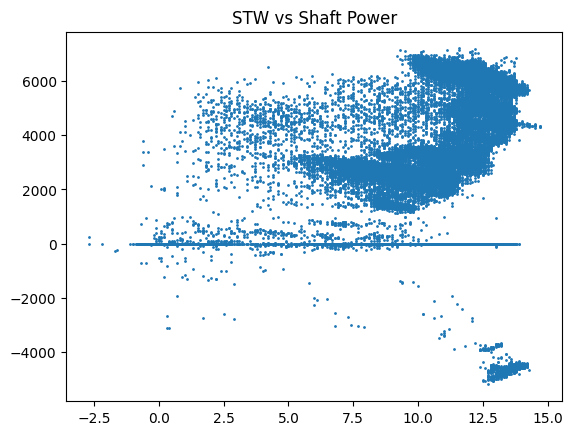

In [22]:
stw_power = metrics_wide.select("stw_kn", "shaft_kw").drop_nulls().sort("stw_kn")
plt.scatter(stw_power["stw_kn"].to_numpy(), stw_power["shaft_kw"].to_numpy(), s=1)
plt.title("STW vs Shaft Power")